# 02 · Manifold — principal-curve trajectory (low-cycling developmental body)

Nath 2021's HGSOC malignant manifold is **non-branching**: over the low-cycling body the
developmental signatures collapse onto a **single dominant axis** — gastrulation+somitogenesis
(Gast/pSom) high at one pole opposed to neural-crest (Crest) rising to a terminal end — rather than
a hub radiating to discrete subtypes with cross-repression. A PPT *tree* over this compact cloud
throws spurious forks (3 branch nodes); the geometry that matters is the signature geography, and
the correct topology is a **principal curve** (ElPiGraph, non-branching by construction) fit on the
*joint* embedding — **not** a re-embedding (the body is compact, aspect ≈ 1.4; re-embedding an
anisotropic compartment fabricates folds).

**Scope decision (derived, not inherited).** 01 resolved a separable **proliferative lobe** (~74%
cycling, proliferation score ≫ 0) alongside the low-cycling body. Per the Kürten / Lin fork we scope
the trajectory to the **`Body`** compartment: the developmental modules are essentially
cell-cycle-free (Gast 0/81, Crest 0/104, pSom 2/98 genes overlap the Regev–Tirosh S+G2M programme)
and Gast is *not* inflated by proliferation, but a cycling state is neither a developmental origin
nor terminus, so it does not belong on the axis. The curve is rooted at the Gast/pSom-high tip and
pseudotime flows to the neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold, scope to the low-cycling Body, score developmental modules
We scope to the `Body` compartment (proliferative lobe removed) and keep those cells on their
*original joint embedding coordinates* — no re-embedding. The three embryonic signatures
(Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union** control pool
and graph-smoothed on the scoped neighbour graph to read geography rather than 10x per-cell dropout.

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells |',
      adata.obs['compartment'].value_counts().to_dict())
sub = adata[adata.obs['compartment'] == 'Body'].copy()
print('scoped Body (developmental trajectory object):', sub.shape[0], 'cells |',
      'cycling fraction %.3f' % sub.obs['cycling'].astype(bool).mean())
sc.pp.neighbors(sub, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
xy = sub.obsm['X_umap']; from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'scoped-body UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f} (compact -> curve on joint coords, no re-embed)')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(sub.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(sub.var_names)]
    sc.tl.score_genes(sub, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): sub.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', sub.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 32484 cells | {'Body': 26703, 'Cycling': 5781}
scoped Body (developmental trajectory object): 26703 cells | cycling fraction 0.078
scoped-body UMAP principal-axis ratio (major/minor singular value): 1.84 (compact -> curve on joint coords, no re-embed)
Gast: 77/81 genes present
pSom: 94/98 genes present
Crest: 100/104 genes present
raw module means (honest readout): {'Gast': -0.0043, 'pSom': 0.0578, 'Crest': -0.0102}


### Verify the axis is developmental, not proliferative
The developmental gene sets are essentially cell-cycle-free (overlap with the Regev–Tirosh S+G2M
programme), the Crest↔Gast anti-correlation holds within the scoped body, and pseudotime will not
track a cycling score (checked after rooting). This confirms scoping the cycling lobe out did not
remove the developmental axis — it removed a confound.

In [6]:
print('smoothed spatial correlations on the scoped body:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(sub.obs[a], sub.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
s_genes = set(('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split())
g2m_genes = set(('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split())
cc = s_genes | g2m_genes
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    ov = set(feat[src]) & cc
    print(f'  {lab}: {len(ov)}/{len(set(feat[src]))} genes overlap the cell-cycle programme')
print('scoped-body cycling fraction: %.3f' % sub.obs['cycling'].astype(bool).mean())

smoothed spatial correlations on the scoped body:
  Gast_sm vs pSom_sm: r = -0.00
  Crest_sm vs Gast_sm: r = -0.41
  Crest_sm vs pSom_sm: r = -0.03
  Gast: 0/81 genes overlap the cell-cycle programme
  pSom: 2/98 genes overlap the cell-cycle programme
  Crest: 0/104 genes overlap the cell-cycle programme
scoped-body cycling fraction: 0.078


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. Fold-freeness and the 2-tip / 0-fork topology are stable across
Nodes = 15/20/30; a PPT tree by contrast throws 3 spurious branch nodes on this compact cloud,
confirming the curve is the correct topology.

In [8]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
# confirm a PPT tree finds no real branching (spurious forks only)
at = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(at, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=2000, ppt_sigma=0.5, seed=SEED, plot=False)
Bt = np.asarray(at.uns['graph']['B'])
print(f'PPT tree(N=20): {int(((Bt>0).sum(0)==1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} branch nodes (spurious on a compact cloud)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.97
curve N=20: 2 tips, 0 forks | self-approach 2.87
curve N=30: 2 tips, 0 forks | self-approach 2.60
PPT tree(N=20): 5 tips, 3 branch nodes (spurious on a compact cloud)
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.87 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin
(Gast/pSom is EARLY, Crest is LATE). Pseudotime then flows to the neural-crest terminus.

In [10]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
print(f'caveat: pseudotime vs cycling score rho = {spearmanr(t, cyc)[0]:+.2f} (cell-cycle-free axis)')

tip 0: Gast=-0.0026 pSom=+0.0707 Crest=-0.0113
tip 2: Gast=-0.0080 pSom=+0.0559 Crest=-0.0037
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.219 p=2.5e-288
  pSom_sm: rho=-0.597 p=0.0e+00
  Crest_sm: rho=+0.213 p=5.0e-272
Neural-crest-high decile mean pseudotime = 0.56
Somitogenesis-high decile mean pseudotime = 0.08
Gastrulation-high decile mean pseudotime = 0.37
caveat: pseudotime vs cycling score rho = -0.06 (cell-cycle-free axis)


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal —
was derived **once in 01** (rotation angle from the manifold's axis of maximal variance; sign from
the developmental-module geography, Gast/pSom-high origin on the left) and stored as `X_umap_lin`.
Every UMAP deliverable across 01–04 re-uses these exact coordinates, so orientation is consistent by
construction (binding). Here we **verify** that layout now that pseudotime exists: the correlation of
the stored `X_umap_lin` x-axis with pseudotime must be strongly positive (low pseudotime =
developmental origin on the left).

In [12]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])   # re-used from 01, not re-derived
if r < 0:      # ensure origin on the left for this dataset's layout
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.4, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.98


### Save manifold + trajectory figure (deliverable)
`uns['epg']` is collapsed to its node positions before writing (the ElPiGraph edge list is a ragged
object array that h5ad cannot serialize). House style: `figsize=(3.5,1.5)`, pseudotime left→right on
`X_umap_lin`, `size=30`, cividis.

saved manifold.h5ad + manifold.pdf | scoped-body cells: 26703


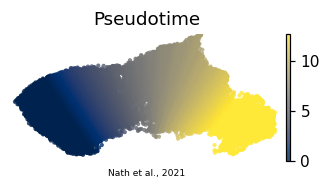

In [14]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Nath et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf | scoped-body cells:', sub.shape[0])